# 04 · Preprocesado del Tema 1: la base curada

Paso 4 de la descarga completa ([plan de la descarga](../../../docs/fase2/mercados_series/PLAN_DESCARGA.md)).
Viene de la [selección y el EDA del paso 3](03_seleccion_eda.ipynb) y de las descargas del paso 3b (3b-1 y 3b-2).

**En una frase:** el paso 4 aplica, **sin tocar la base de trabajo**, la lista curada y el plan de preprocesado
del paso 3, más el corte G2, y escribe en el corpus una **base curada** de series y unos **precios curados**. Es lo
que leen los agentes y el backtest. Las fechas de publicación **solo se retrasan, nunca se adelantan**, y nada
publicado después del corte entra.

Este notebook lee tablas de metadatos del repo, los YAML, el manifiesto de la base curada y, del registro de
cambios (en `D:`), solo columnas de fechas y marcas para agregarlas. **No lee la base ni muestra ningún valor de
serie ni precio**, y todas las cifras salen de las celdas.

**Vocabulario** (lo que no se explicó en el [03](03_seleccion_eda.ipynb)):

- **Base de trabajo** (`base_series.parquet`): todas las series con sus fechas originales; se usa para auditar y
  construir. **Base curada** (`base_curada.parquet`): solo las series que se quedan, con las fechas del plan.
- **3b-1 y 3b-2**: las dos tandas de descargas del paso 3b, ya hechas. La 3b-1 (alcance H1: S&P 500 y lo básico) y
  la 3b-2 (lo internacional, el universo UCITS, las ediciones del WEO que sirve la API y los agregados).
- **Corte G2** (decisión G2 del 3b): una fecha final común para todo el dataset; nada publicado después entra en la
  base curada ni en los precios curados.
- **Capa**: cada parte del plan que puede retrasar una fecha de publicación. La capa 1 son las reglas por grupo:
  **E4**, la regla conservadora de las series cuya fecha no se puede medir (la fecha más tardía plausible según el
  calendario de la fuente), y **E5**, el **tramo conservador** de las series cuya regla adelantaba (antes de la fecha
  desde la que son fiables se usa la regla más el mayor adelanto medido más un margen). La capa 2 es H.15 diario
  antiguo y la capa 3, los índices **reconstruidos** hacia atrás. Aparte, las **derivadas** (calculadas con otras
  series) se recalculan con sus componentes curados.
- **Registro de cambios** (`registro_cambios.parquet`): una fila por cada fila de la base que cambia de fecha, de
  escala o de unidad, con la fecha antes y después; sin valores.
- **Relleno**: velas y aperturas que Yahoo inventa repitiendo el cierre (`open == close` y `high == low`, o velas en
  días cerrados sin volumen). No existieron.
- **Manifiesto** (`curada_manifiesto.json`): la ficha de la construcción, con el tamaño, la fecha y la firma SHA-256
  de lo que entró y de lo que salió.
- **TimeGate**: la regla de las tools que no deja ver nada publicado después de la fecha que se pide.

In [1]:
%matplotlib inline
%config InlineBackend.figure_formats = ['png']
import fnmatch
import hashlib
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow.parquet as pq
import yaml
from IPython.display import Markdown, display
from matplotlib.patches import Patch

from ingesta.comun.rutas import corpus_dir, resultados_dir
from ingesta.mercados_series import preprocesado, tools

plt.rcParams.update({'figure.dpi': 80, 'savefig.dpi': 80, 'font.size': 9, 'axes.titlesize': 11,
                     'axes.titleweight': 'bold', 'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.facecolor': 'white'})
pd.set_option('display.max_rows', 40)
pd.set_option('display.max_colwidth', 100)

# Paleta del 03: decisión (queda / alias / proyecciones / fuera) y trato de la fecha (verde sin aviso; naranjas
# conservadores, más oscuro cuanto más conservador)
COL_DEC = {'queda': '#2b8a3e', 'alias': '#74c0fc', 'proyecciones': '#b197fc', 'fuera': '#ced4da'}
COL_TRATO = {'entra sin aviso': '#2b8a3e', 'entra con tramo conservador (E5)': '#ffa94d',
             'entra con aviso y regla conservadora (E4)': '#d9480f'}
COL_P = {'alta': '#c92a2a', 'media': '#ff8787', 'baja': '#ffd8d8'}
COL_OK, COL_MAL, COL_NA = '#2b8a3e', '#e03131', '#adb5bd'
COL_VELA = '#495057'                                  # velas de relleno quitadas (neutro)
COL_LIM = '#e9ecef'                                   # limitación declarada (gris rayado, como en el 03)
GRUPO_TXT = {'mercado_diario': 'mercado diario', 'banco_mundial': 'Banco Mundial',
             'macro_eurostat_bce_bis': 'macro Eurostat, BCE y BIS', 'academicas': 'académicas',
             'otras_fred': 'otras de FRED', 'no_fiable': 'no fiable', 'fiable_con_margen': 'fiable con margen'}


def es(x, d=0):
    # número en formato español: 1.434 · 0,95
    s = f'{x:,.{d}f}'
    return s.replace(',', '§').replace('.', ',').replace('§', '.')


def dias(x):
    return f"{es(x)} {'día' if x == 1 else 'días'}"


def tarjetas(items, filas, cols, titulo, alto=3.3):
    # cuadrícula de tarjetas (cifra, etiqueta, subtítulo, color), como el resumen del 03
    fig, axs = plt.subplots(filas, cols, figsize=(12.5, alto), gridspec_kw={'wspace': .06, 'hspace': .12})
    for ax in np.ravel(axs):
        ax.axis('off')
    for ax, (cifra, etq, sub, color) in zip(np.ravel(axs), items):
        ax.add_patch(plt.Rectangle((0, 0), 1, 1, fc='#f8f9fa', ec='#dee2e6', transform=ax.transAxes))
        ax.add_patch(plt.Rectangle((0, 0), .035, 1, fc=color, ec='none', transform=ax.transAxes))
        ax.text(.1, .66, cifra, fontsize=18, fontweight='bold', color='#212529', va='center', transform=ax.transAxes)
        ax.text(.1, .36, etq, fontsize=9.5, fontweight='bold', color='#495057', va='center', transform=ax.transAxes)
        ax.text(.1, .15, sub, fontsize=7.5, color='#495057', va='center', transform=ax.transAxes)
    fig.suptitle(titulo, fontweight='bold', x=.01, ha='left')
    fig.subplots_adjust(left=.01, right=.99, top=.86, bottom=.02)
    plt.show()


T = resultados_dir('mercados_series') / 'tablas'
SERIES_DIR = corpus_dir('mercados_series') / 'series'
cur = pd.read_csv(T / 'curada_resumen.csv')
ver_s = pd.read_csv(T / 'curada_verificaciones.csv')
pcr = pd.read_csv(T / 'precios_curados_resumen.csv', dtype={'ticker': str})
pav = pd.read_csv(T / 'precios_curados_avisos.csv', dtype={'ticker': str})
ver_p = pd.read_csv(T / 'precios_curados_verificaciones.csv')
est = pd.read_csv(T / 'descargas_3b_estado.csv')
sp5 = pd.read_csv(T / 'sp500_cobertura_3b1.csv').rename(columns={'valor': 'dato'})
san = pd.read_csv(T / 'solo_anadir_ultima.csv')
sim = pd.read_csv(T / 'preprocesado_simulacion.csv')
inv = pd.read_csv(T / 'inventario_series.csv')
PLAN = preprocesado.cargar_plan()
LISTA_YAML = yaml.safe_load(preprocesado.RUTA_LISTA.read_text(encoding='utf-8'))
LISTA, LISTA_P = LISTA_YAML['series'], {str(k): v for k, v in LISTA_YAML['precios'].items()}
MAN = json.loads((SERIES_DIR / 'curada_manifiesto.json').read_text(encoding='utf-8'))
CORTE = pd.Timestamp(MAN['corte_g2'])

# Registro de cambios: solo columnas de fechas y marcas (el fichero no tiene valores), para agregarlas aquí
COLS_REG = ['serie', 'fecha_referencia', 'fecha_publicacion_antes', 'fecha_publicacion_despues', 'retraso_dias',
            'seccion', 'grupo', 'reconstruida', 'h15', 'derivada', 'escala', 'homogeneizacion', 'con_tope', 'factor_escala',
            'unidad_antes', 'unidad_despues', 'en_base_curada']
ruta_reg = SERIES_DIR / 'registro_cambios.parquet'
assert not {'valor', 'valor_antes', 'valor_despues'} & set(pq.read_schema(ruta_reg).names), 'el registro trae valores'
reg = pq.read_table(ruta_reg, columns=COLS_REG).to_pandas()

dec = pd.Series({k: v['decision'] for k, v in LISTA.items()})
dec_p = pd.Series({k: v['decision'] for k, v in LISTA_P.items()})
n = lambda m: int(np.sum(m))
assert len(reg) == MAN['salidas']['registro_cambios']['filas'], 'el registro no casa con el manifiesto'
assert len(cur) == MAN['resumen']['series_curada'] == n(dec == 'queda'), 'curada_resumen no casa con la lista'
assert set(pcr['ticker']) == set(dec_p[dec_p == 'queda'].index), 'precios curados ≠ tickers «queda» de la lista'
print(f"Lista curada: {es(len(dec))} series ({', '.join(f'{k} {es(v)}' for k, v in dec.value_counts().items())}) y "
      f"{es(len(dec_p))} tickers ({', '.join(f'{k} {es(v)}' for k, v in dec_p.value_counts().items())}).")
print(f"Registro de cambios: {es(len(reg))} filas (columnas leídas: {len(COLS_REG)}). Corte G2: {CORTE.date()}. "
      'curada_resumen.csv, precios_curados_resumen.csv, el registro y el manifiesto cuadran con la lista.')

Lista curada: 1.521 series (fuera 570, queda 533, proyecciones 309, alias 109) y 1.624 tickers (queda 1.616, fuera 8).
Registro de cambios: 1.501.271 filas (columnas leídas: 17). Corte G2: 2026-11-13. curada_resumen.csv, precios_curados_resumen.csv, el registro y el manifiesto cuadran con la lista.


## 0. Resumen ejecutivo

**Qué se ve:** las cifras clave del paso, calculadas aquí a partir de las tablas, el manifiesto y el registro.
**Conclusión:** la base curada está construida y verificada; las conclusiones, debajo de las tarjetas.

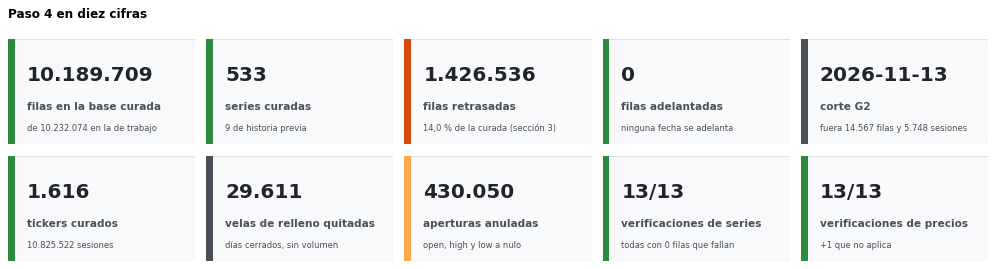

- **La base curada es la de trabajo con fechas más prudentes, no otra base:** tiene 10.189.709 filas de 533 series; solo se retrasan 14,0 % de las filas y ninguna se adelanta (el registro cuenta más filas porque también apunta las que solo cambian de escala o unidad y las que el corte deja fuera; la sección 3 lo cuadra). Los retrasos grandes (más de 30 días) caen sobre todo en la historia anterior a 2000 (81 % de ellos).
- **Los precios curados quitan lo que no existió:** 29.611 velas de relleno en días cerrados y 430.050 aperturas de relleno pasan a nulo, porque la decisión de t se ejecuta a la apertura de t+1 y esa apertura tiene que ser real. Los cierres no cambian.
- **Todo cuadra:** 26 de 26 verificaciones dan 0 fallos (ninguna falla) y el manifiesto ata la base curada a la base de trabajo y a los dos YAML de los que sale (sección 5).

In [2]:
ret = reg[reg['en_base_curada'] & (reg['retraso_dias'] > 0)]
ok_s, ok_p = n(ver_s['filas_fallan'] == 0), n(ver_p['estado'] == 'ok')
na_p = n(ver_p['estado'] == 'no aplica')
fallan = n(ver_s['filas_fallan'] > 0) + n(~ver_p['estado'].isin(['ok', 'no aplica']))
adel = int(ver_s.set_index('verificacion').loc['no_adelanta', 'filas_fallan'])
R = MAN['resumen']
TARJ = [
    (es(R['filas_curada']), 'filas en la base curada', f"de {es(R['filas_base'])} en la de trabajo", COL_DEC['queda']),
    (es(R['series_curada']), 'series curadas', f"{n(cur['rol'] == 'historia_previa')} de historia previa", COL_DEC['queda']),
    (es(len(ret)), 'filas retrasadas', f"{es(100 * len(ret) / R['filas_curada'], 1)} % de la curada (sección 3)",
     COL_TRATO['entra con aviso y regla conservadora (E4)']),
    (es(adel), 'filas adelantadas', 'ninguna fecha se adelanta', COL_OK if adel == 0 else COL_MAL),
    (str(CORTE.date()), 'corte G2', f"fuera {es(R['filas_cortadas'])} filas y {es(pcr['fuera_corte'].sum())} sesiones",
     '#495057'),
    (es(len(pcr)), 'tickers curados', f"{es(pcr['sesiones_despues'].sum())} sesiones", COL_DEC['queda']),
    (es(pcr['velas_quitadas'].sum()), 'velas de relleno quitadas', 'días cerrados, sin volumen', COL_VELA),
    (es(pcr['aperturas_anuladas'].sum()), 'aperturas anuladas', 'open, high y low a nulo', COL_TRATO['entra con tramo conservador (E5)']),
    (f'{ok_s}/{len(ver_s)}', 'verificaciones de series', 'todas con 0 filas que fallan' if ok_s == len(ver_s)
     else 'ALGUNA FALLA', COL_OK if ok_s == len(ver_s) else COL_MAL),
    (f'{ok_p}/{len(ver_p) - na_p}', 'verificaciones de precios', f'+{na_p} que no aplica' if na_p else 'todas bien',
     COL_OK if ok_p == len(ver_p) - na_p else COL_MAL),
]
tarjetas(TARJ, 2, 5, 'Paso 4 en diez cifras')

viejo = ret['fecha_referencia'].dt.year < 2000
grande = ret['retraso_dias'] > 30
display(Markdown(
    f"- **La base curada es la de trabajo con fechas más prudentes, no otra base:** tiene {es(R['filas_curada'])} "
    f"filas de {R['series_curada']} series; solo se retrasan {es(100 * len(ret) / R['filas_curada'], 1)} % de las "
    f"filas y {'ninguna se adelanta' if adel == 0 else f'{adel} se adelantan'} (el registro cuenta más filas porque "
    "también apunta las que solo cambian de escala o unidad y las que el corte deja fuera; la sección 3 lo cuadra). "
    f"Los retrasos grandes (más de "
    f"{dias(30)}) caen sobre todo en la historia anterior a 2000 ({es(100 * viejo[grande].mean())} % de ellos).\n"
    f"- **Los precios curados quitan lo que no existió:** {es(pcr['velas_quitadas'].sum())} velas de relleno en "
    f"días cerrados y {es(pcr['aperturas_anuladas'].sum())} aperturas de relleno pasan a nulo, porque la decisión de "
    "t se ejecuta a la apertura de t+1 y esa apertura tiene que ser real. Los cierres no cambian.\n"
    f"- **Todo cuadra:** {ok_s + ok_p} de {len(ver_s) + len(ver_p) - na_p} verificaciones dan 0 fallos "
    f"({'ninguna falla' if fallan == 0 else f'{fallan} fallan'}) y el manifiesto ata la base curada a la base de "
    "trabajo y a los dos YAML de los que sale (sección 5)."))

## 1. De dónde venimos: el paso 3b (3b-1 + 3b-2) y el corte G2

**Qué se ve:** el estado de cada fila de la lista del 3b tras sus dos tandas (`descargas_3b_estado.csv`), por tipo,
lo que aportó la 3b-2 y qué quita el corte G2. **Conclusión:** el 3b refrescó todo lo que se queda y descargó lo que
tenía fuente gratuita y legal (la 3b-1, EE. UU. y lo básico; la 3b-2, lo internacional, el universo UCITS, el WEO
reciente y los agregados); lo que no la tiene queda como limitación declarada y casi nada queda aplazado. El corte
fija una fecha común para todo el dataset.

En `descargas_3b_estado.csv` **la columna que vale es `estado_3b`** (el resultado del 3b, con su motivo en
`motivo_3b`). La columna `estado` es la del paso 3 (pendiente o limitación declarada) y se conserva solo como
referencia; la tabla de debajo de la figura cruza las dos.

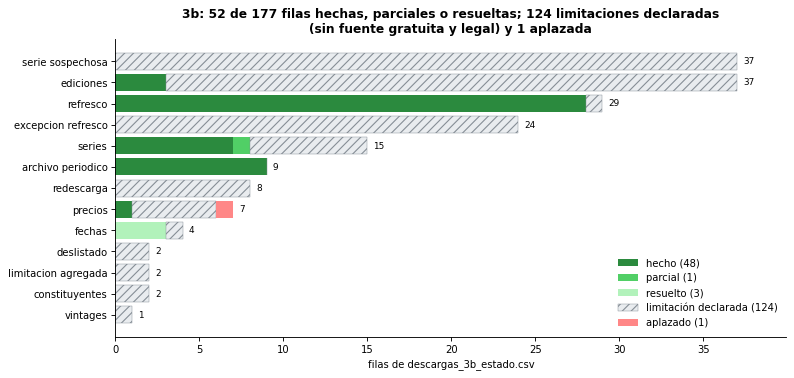

Hechas: refresco 28, archivo_periodico 9, series 7, ediciones 3, precios 1


estado_3b (el que vale),hecho,parcial,resuelto,limitacion_declarada,aplazado
estado (paso 3),,,,,
limitacion_declarada,0,0,0,44,0
pendiente,41,1,3,53,1


In [3]:
EST = ['hecho', 'parcial', 'resuelto', 'limitacion_declarada', 'aplazado']
COL_EST = {'hecho': COL_OK, 'parcial': '#51cf66', 'resuelto': '#b2f2bb', 'limitacion_declarada': COL_LIM,
           'aplazado': COL_P['media']}
ETQ_EST = {'hecho': 'hecho', 'parcial': 'parcial', 'resuelto': 'resuelto', 'limitacion_declarada': 'limitación declarada',
           'aplazado': 'aplazado'}
assert set(est['estado_3b']) <= set(EST), f"estados nuevos en estado_3b: {set(est['estado_3b']) - set(EST)}"
ct = pd.crosstab(est['tipo'], est['estado_3b']).reindex(columns=EST, fill_value=0)
ct = ct.loc[ct.sum(axis=1).sort_values().index]
fig, ax = plt.subplots(figsize=(10, 4.8))
izq = np.zeros(len(ct))
tot_e = est['estado_3b'].value_counts()
for e in EST:
    ax.barh(ct.index.str.replace('_', ' '), ct[e], left=izq, color=COL_EST[e], label=f'{ETQ_EST[e]} ({tot_e.get(e, 0)})',
            ec='#868e96' if e == 'limitacion_declarada' else 'none', lw=.4, hatch='///' if e == 'limitacion_declarada' else None)
    izq += ct[e].to_numpy()
tope_x = ct.sum(axis=1).max()
for y, k in enumerate(ct.sum(axis=1)):
    ax.text(k + tope_x * .01, y, str(k), va='center', fontsize=8)
ax.set_xlim(0, tope_x * 1.08)
hechas = tot_e.get('hecho', 0) + tot_e.get('parcial', 0) + tot_e.get('resuelto', 0)
ax.set_title(f"3b: {hechas} de {len(est)} filas hechas, parciales o resueltas; {tot_e.get('limitacion_declarada', 0)} "
             f"limitaciones declaradas\n(sin fuente gratuita y legal) y {tot_e.get('aplazado', 0)} "
             f"{'aplazada' if tot_e.get('aplazado', 0) == 1 else 'aplazadas'}")
ax.set_xlabel('filas de descargas_3b_estado.csv')
ax.legend(frameon=False, loc='lower right')
plt.tight_layout()
plt.show()
print('Hechas:', ', '.join(f'{t} {k}' for t, k in est[est['estado_3b'] == 'hecho']['tipo'].value_counts().items()))
pd.crosstab(est['estado'], est['estado_3b']).reindex(columns=EST, fill_value=0).rename_axis(
    index='estado (paso 3)', columns='estado_3b (el que vale)')

**Lo que aportó la 3b-2**, contado aquí a partir del estado del 3b y de los registros de descarga de Yahoo (solo
metadatos: tickers y estado de la descarga):

In [4]:
LOGS = corpus_dir('mercados_series') / 'logs'
amp = pd.read_csv(T / 'yahoo_3b2_ampliado.csv', dtype={'ticker': str})
ruta_uni = LOGS / 'yahoo_3b2_universo.jsonl'
uni = pd.read_json(ruta_uni, lines=True, dtype={'ticker': str}) if ruta_uni.exists() else pd.DataFrame(columns=['ticker', 'estado'])
uni = uni.drop_duplicates('ticker', keep='last')
hecho = est[est['estado_3b'].isin(['hecho', 'parcial'])]
ed = sorted(hecho.loc[hecho['tipo'] == 'ediciones', 'id'].str.split(':').str[-1])
ag_weo = hecho.loc[hecho['id'].str.startswith('imf:WEO.'), 'id'].tolist()
ag_bm = hecho.loc[hecho['id'].str.startswith('wb:'), 'id'].tolist()
rba = hecho.loc[hecho['id'].str.startswith('rba:'), 'id'].tolist()
display(Markdown(
    f"> **La 3b-2 en una línea por bloque**\n>\n"
    f"> - **Universo:** {n(uni['estado'] == 'ok')} instrumentos del universo descargados (UCITS de Londres y Xetra y el "
    "resto fuera del S&P 500 y del núcleo).\n"
    f"> - **Acciones no estadounidenses:** {n(amp['estado'] == 'ok')} refrescadas hasta el corte "
    f"({n(amp['estado'] != 'ok')} con error de descarga).\n"
    f"> - **WEO:** ediciones {', '.join(ed)} y sus agregados ({', '.join(ag_weo)}).\n"
    f"> - **Banco Mundial:** agregados {', '.join(ag_bm)}.\n"
    f"> - **RBA:** historia anterior a 2011 ({', '.join(rba)})."))

> **La 3b-2 en una línea por bloque**
>
> - **Universo:** 125 instrumentos del universo descargados (UCITS de Londres y Xetra y el resto fuera del S&P 500 y del núcleo).
> - **Acciones no estadounidenses:** 613 refrescadas hasta el corte (12 con error de descarga).
> - **WEO:** ediciones 2025-04, 2025-10, 2026-04 y sus agregados (imf:WEO.001, imf:WEO.163, imf:WEO.200).
> - **Banco Mundial:** agregados wb:EMU, wb:LMY, wb:WLD.
> - **RBA:** historia anterior a 2011 (rba:historia_pre2011).

**El corte G2.** Las fuentes del 3b acaban en días distintos; el paso 4 deja fuera de la base curada y de los
precios curados todo lo publicado después del corte, para que el dataset tenga una sola fecha final. La base de
trabajo y el crudo conservan lo posterior para el siguiente refresco. Abajo, qué quita y hasta dónde llega cada
ticker curado: los que acaban antes del corte son los que Yahoo no deja refrescar (aviso `no_llega_corte`, sección 9)
o dejaron de cotizar.

In [5]:
print(f"Corte G2: {CORTE.date()} (manifiesto). Quita {es(R['filas_cortadas'])} filas de "
      f"{n(cur['filas_cortadas'] > 0)} series, {R['proyecciones_cortadas']} filas de proyecciones y "
      f"{es(pcr['fuera_corte'].sum())} sesiones de {n(pcr['fuera_corte'] > 0)} tickers.")
print(f"Ninguna serie curada publicada después del corte: {n(pd.to_datetime(cur['publicada_hasta']) > CORTE) == 0}; "
      f"ningún ticker curado con sesión posterior: {n(pd.to_datetime(pcr['hasta']) > CORTE) == 0}.")
h = pd.to_datetime(pcr['hasta'])
tramos = pd.cut((CORTE - h).dt.days, [-1, 0, 7, 45, 10**6],
                labels=['acaba en el corte', 'hasta 1 semana antes', '1 semana a 45 días antes', 'más de 45 días antes'])
pcr.assign(fin=tramos).groupby('fin', observed=False).agg(
    tickers=('ticker', 'size'), ejemplos=('ticker', lambda s: ', '.join(s.head(4))))

Corte G2: 2026-11-13 (manifiesto). Quita 14.567 filas de 292 series, 9 filas de proyecciones y 5.748 sesiones de 1596 tickers.
Ninguna serie curada publicada después del corte: True; ningún ticker curado con sesión posterior: True.


,tickers,ejemplos
fin,,
acaba en el corte,1555,"000080.KS, 0001.HK, 000100.KS, 000120.KS"
hasta 1 semana antes,40,"cb:BTC-USD, cb:ETH-USD, 6E=F, AUDUSD=X"
1 semana a 45 días antes,19,"000001.SS, ALC.SW, CFR.SW, EXO.AS"
más de 45 días antes,2,"DWD, GR"


**Fuentes que solo crecen.** Al refrescar, las fuentes sin historia de revisiones (BCE) no pueden reescribir lo ya
guardado: los datos anteriores se conservan y una revisión se fecha el día en que se observó. `solo_anadir_ultima.csv`
cuenta, por serie, qué hizo el último refresco (solo recuentos):

In [6]:
san

,serie,observado,conservadas,ya_conservadas,fechadas_observacion,mismo_valor,fecha_propia,guardada_gana_valor,guardada_gana_nota,fecha_corregida
0,bis:WS_EER.M.R.B.CA,2026-11-20,0,0,0,0,0,5,0,0
1,bis:WS_EER.M.R.B.CN,2026-11-20,0,0,0,0,0,9,0,0
2,bis:WS_EER.M.R.B.DE,2026-11-20,0,0,0,0,0,7,0,0
3,bis:WS_EER.M.R.B.FR,2026-11-20,0,0,0,0,0,7,0,0
4,bis:WS_EER.M.R.B.GB,2026-11-20,0,0,0,0,0,14,0,0
...,...,...,...,...,...,...,...,...,...,...
37,eurostat:une_rt_m.M.SA.TOTAL.PC_ACT.T.EA21,2026-11-20,0,0,0,0,0,4,0,0
38,eurostat:une_rt_m.M.SA.TOTAL.PC_ACT.T.EU27_2020,2026-11-20,0,0,0,0,0,3,0,0
39,eurostat:une_rt_m.M.SA.TOTAL.PC_ACT.T.FR,2026-11-20,0,0,0,0,0,11,0,0
40,eurostat:une_rt_m.M.SA.TOTAL.PC_ACT.T.IT,2026-11-20,0,0,0,0,0,13,0,0


## 2. La base curada frente a la de trabajo

**Qué se ve:** de dónde sale cada serie y cada fila de la base curada. A la izquierda, cada decisión de la lista va a
su destino; a la derecha, el embudo de filas. **Conclusión:** la base curada es un subconjunto de la de trabajo
(solo las series «queda», también las de historia previa); los alias y las proyecciones van a sus tablas, sin
mezclarse, y las únicas filas que se pierden son las de series que no se quedan, las posteriores al corte y unas
pocas de una derivada con la ventana incompleta.

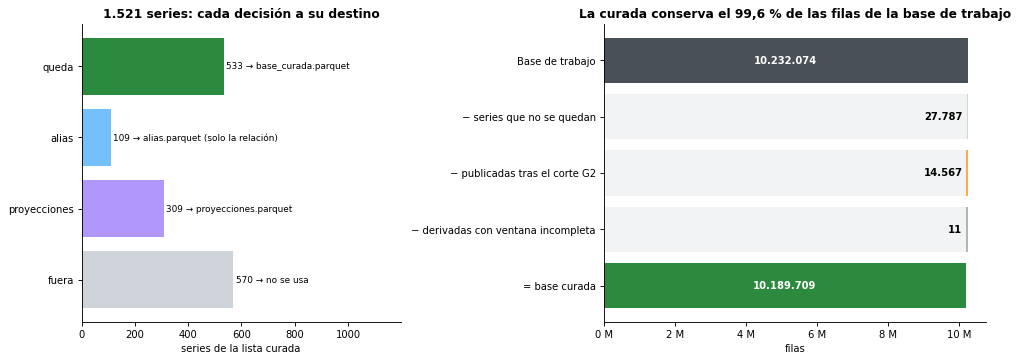

,trabajo,curada
filas,10.232.074,10.189.709
series,1.521,533
tabla de alias,—,109 alias
tabla de proyecciones,—,"309 series, 1.340 filas"


In [7]:
DESTINO = {'queda': 'base_curada.parquet', 'alias': 'alias.parquet (solo la relación)',
           'proyecciones': 'proyecciones.parquet', 'fuera': 'no se usa'}
SAL = MAN['salidas']
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 4.6), gridspec_kw={'width_ratios': [1, 1.2]})
vc = dec.value_counts().reindex(['queda', 'alias', 'proyecciones', 'fuera'])
a1.barh(range(len(vc)), vc, color=[COL_DEC[k] for k in vc.index])
for y, (k, v) in enumerate(vc.items()):
    a1.text(v + 8, y, f'{v} → {DESTINO[k]}', va='center', fontsize=8)
a1.set_yticks(range(len(vc)), [f'{k}' for k in vc.index])
a1.invert_yaxis()
a1.set_xlim(0, vc.max() * 2.1)
a1.set_xlabel('series de la lista curada')
a1.set_title(f'{es(len(dec))} series: cada decisión a su destino')

pasos = [('Base de trabajo', R['filas_base'], '#495057'),
         ('− series que no se quedan', R['filas_base'] - R['filas_queda_base'], COL_DEC['fuera']),
         ('− publicadas tras el corte G2', R['filas_cortadas'], '#ffa94d'),
         ('− derivadas con ventana incompleta', R['filas_queda_base'] - R['filas_cortadas'] - R['filas_curada'], '#adb5bd'),
         ('= base curada', R['filas_curada'], COL_DEC['queda'])]
resto = R['filas_base']
for i, (etq, k, color) in enumerate(pasos):
    y = len(pasos) - 1 - i
    if i in (0, len(pasos) - 1):
        a2.barh(y, k, color=color)
        a2.text(k / 2, y, es(k), ha='center', va='center', color='white', fontweight='bold')
    else:
        resto -= k
        a2.barh(y, resto, color='#f1f3f5')
        a2.barh(y, max(k, R['filas_base'] * .004), left=resto, color=color)
        a2.text(resto - R['filas_base'] * .01, y, es(k), ha='right', va='center', fontweight='bold')
a2.set_yticks(range(len(pasos)), [p[0] for p in reversed(pasos)])
a2.set_xlabel('filas')
a2.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x / 1e6:.0f} M'))
a2.set_title(f"La curada conserva el {es(100 * R['filas_curada'] / R['filas_base'], 1)} % de las filas de la base de trabajo")
plt.tight_layout()
plt.show()

pd.DataFrame({
    'trabajo': [es(R['filas_base']), es(len(inv)), '—', '—'],
    'curada': [es(R['filas_curada']), es(R['series_curada']), f"{es(SAL['alias']['filas'])} alias",
               f"{R['proyecciones_series']} series, {es(SAL['proyecciones']['filas'])} filas"],
}, index=['filas', 'series', 'tabla de alias', 'tabla de proyecciones'])

## 3. Qué fechas cambian y cuánto

**Qué se ve:** cada fila retrasada del registro de cambios, por **capa** del plan (ver el vocabulario):

- **E4**: regla conservadora de las fechas no medibles, por grupo;
- **E5**: tramo no fiable o fiable con margen;
- **reconstruidas**: índices creados en una fecha (`publicado_desde`) cuya historia anterior se calculó después; las del
  catálogo y las de fechas de creación externas (F1–F2);
- **H.15**: el diario de la Fed antes de `h15_diario.hasta`;
- **derivadas**: recalculadas con sus componentes curados.

Cuando una fila cae en varias capas, cuenta en la más fuerte (reconstruida > E5 > E4 > H.15 > derivada). El **tope del
primer vintage** no es una capa: para algunas filas de E4 y E5 impide pasar de la fecha del primer vintage de ALFRED.

**Conclusión:** casi todas las filas se retrasan poco (un día en el mercado diario, una semana en H.15); los retrasos
de años son de los índices reconstruidos, cuya historia antigua no existía en su fecha. Por eso los retrasos grandes se
concentran en la historia antigua, mientras que el día de margen del mercado diario se reparte por todos los años.

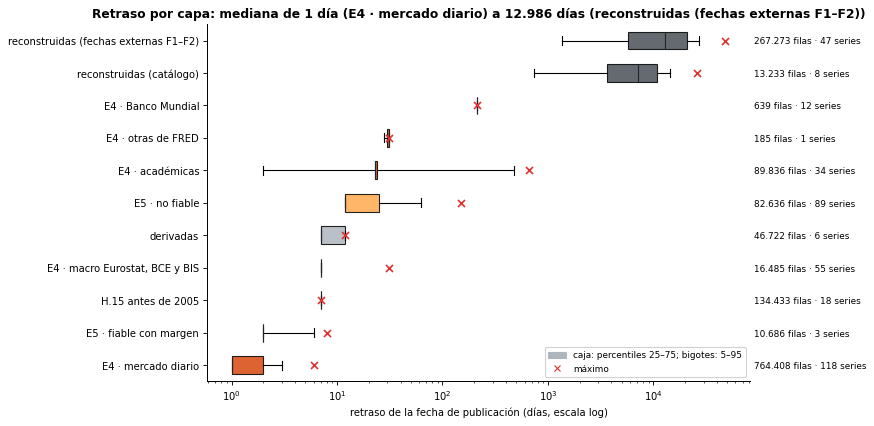

Tope del primer vintage de ALFRED: 108 filas de E4/E5 se quedan en la fecha de su primer vintage (no pasan de ella, para no desordenar los vintages reales).


,series,filas,mediana,p95,máximo
capa,,,,,
E4 · mercado diario,118,764408,1.0,3.0,6.0
E5 · fiable con margen,3,10686,2.0,6.0,8.0
H.15 antes de 2005,18,134433,7.0,7.0,7.0
"E4 · macro Eurostat, BCE y BIS",55,16485,7.0,7.0,31.0
derivadas,6,46722,7.0,12.0,12.0
E5 · no fiable,89,82636,12.0,63.0,151.0
E4 · académicas,34,89836,23.0,480.0,662.0
E4 · otras de FRED,1,185,31.0,31.0,31.0
E4 · Banco Mundial,12,639,212.0,213.0,213.0


In [8]:
REC_CAT = set(PLAN['reconstruidas']['series'])
EXT = PLAN['reconstruidas']['externas']
claves = ['serie', 'seccion', 'grupo', 'reconstruida', 'h15', 'derivada']
u = ret[claves].drop_duplicates()


def capa(r_):
    if r_['reconstruida']:
        return 'reconstruidas (catálogo)' if r_['serie'] in REC_CAT else 'reconstruidas (fechas externas F1–F2)'
    if r_['seccion'] == 'tramo_no_fiable':
        return 'E5 · ' + GRUPO_TXT.get(r_['grupo'], str(r_['grupo']))
    if r_['seccion'] == 'reglas_conservadoras':
        return 'E4 · ' + GRUPO_TXT.get(r_['grupo'], str(r_['grupo']))
    if r_['h15']:
        return f"H.15 antes de {PLAN['h15_diario']['hasta'][:4]}"
    if r_['derivada']:
        return 'derivadas'
    return 'otra'


u['capa'] = u.apply(capa, axis=1)
ret = ret.merge(u, on=claves, how='left')
ext_ok = ret.loc[ret['capa'].str.contains('externas'), 'serie'].map(lambda s: any(fnmatch.fnmatch(s, p) for p in EXT))
assert ext_ok.all(), 'una reconstruida externa no casa con preprocesado.yaml (reconstruidas.externas)'
q = ret.groupby('capa')['retraso_dias'].describe(percentiles=[.05, .25, .5, .75, .95])
q['series'] = ret.groupby('capa')['serie'].nunique()
q = q.sort_values('50%')


def color_capa(k):
    return (COL_TRATO['entra con aviso y regla conservadora (E4)'] if k.startswith('E4') else
            COL_TRATO['entra con tramo conservador (E5)'] if k.startswith('E5') else
            '#495057' if k.startswith('reconstruidas') else '#868e96' if k.startswith('H.15') else '#adb5bd')


fig, ax = plt.subplots(figsize=(11, 5.4))
stats = [{'label': k, 'whislo': r_['5%'], 'q1': r_['25%'], 'med': r_['50%'], 'q3': r_['75%'], 'whishi': r_['95%'],
          'fliers': []} for k, r_ in q.iterrows()]
bp = ax.bxp(stats, vert=False, widths=.55, showfliers=False, patch_artist=True, medianprops={'color': '#212529'})
for caja, k in zip(bp['boxes'], q.index):
    caja.set_facecolor(color_capa(k))
    caja.set_alpha(.85)
ax.scatter(q['max'], range(1, len(q) + 1), marker='x', color=COL_MAL, s=40, zorder=4)
ax.set_xscale('log')
ax.set_xlabel('retraso de la fecha de publicación (días, escala log)')
der = ax.twinx()
der.set_ylim(ax.get_ylim())
der.set_yticks(range(1, len(q) + 1), [f"{es(r_['count'])} filas · {int(r_['series'])} series" for _, r_ in q.iterrows()],
               fontsize=8)
der.tick_params(length=0)
der.spines[['top', 'right']].set_visible(False)
ax.set_title(f"Retraso por capa: mediana de {dias(q['50%'].iloc[0])} ({q.index[0]}) a "
             f"{dias(q['50%'].iloc[-1])} ({q.index[-1]})")
ax.legend(handles=[Patch(color='#adb5bd', label='caja: percentiles 25–75; bigotes: 5–95'),
                   plt.Line2D([], [], marker='x', ls='', color=COL_MAL, label='máximo')],
          loc='lower right', fontsize=8, framealpha=.9)
plt.tight_layout()
plt.show()

tope = n(reg['con_tope'])
print(f"Tope del primer vintage de ALFRED: {tope} filas de E4/E5 se quedan en la fecha de su primer vintage "
      "(no pasan de ella, para no desordenar los vintages reales).")
q.rename(columns={'count': 'filas', '50%': 'mediana', '95%': 'p95', 'max': 'máximo'})[
    ['series', 'filas', 'mediana', 'p95', 'máximo']].astype({'filas': int})

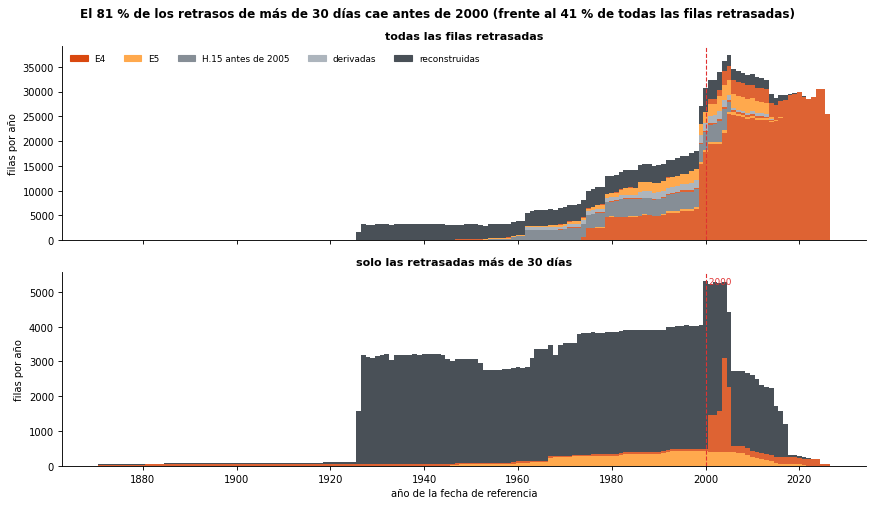

In [9]:
anio = ret['fecha_referencia'].dt.year
ORDEN_C = list(q.index)
ct_a = pd.crosstab(anio, ret['capa']).reindex(columns=ORDEN_C, fill_value=0)
gr = ret[ret['retraso_dias'] > 30]
ct_g = pd.crosstab(gr['fecha_referencia'].dt.year, gr['capa']).reindex(index=ct_a.index, columns=ORDEN_C, fill_value=0)
fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 6.4), sharex=True)
for ax, tabla, tit in ((a1, ct_a, 'todas las filas retrasadas'), (a2, ct_g, f'solo las retrasadas más de {dias(30)}')):
    abajo = np.zeros(len(tabla))
    for k in ORDEN_C:
        ax.bar(tabla.index, tabla[k], bottom=abajo, width=1, color=color_capa(k), alpha=.85 if 'E4' in k else 1,
               edgecolor='none')
        abajo += tabla[k].to_numpy()
    ax.set_ylabel('filas por año')
    ax.set_title(tit, fontsize=10)
    ax.axvline(2000, color='#e03131', ls='--', lw=1)
a2.set_xlabel('año de la fecha de referencia')
cols_leg = {}
for k in ORDEN_C:
    clave = k.split(' · ')[0] if ' · ' in k else ('reconstruidas' if k.startswith('reconstruidas') else k)
    cols_leg.setdefault(clave, color_capa(k))
a1.legend(handles=[Patch(color=c, label=k) for k, c in cols_leg.items()], ncol=5, fontsize=8, frameon=False, loc='upper left')
a2.text(2000, a2.get_ylim()[1] * .97, ' 2000', color='#e03131', fontsize=8, va='top')
fig.suptitle(f"El {es(100 * (gr['fecha_referencia'].dt.year < 2000).mean())} % de los retrasos de más de {dias(30)} "
             f"cae antes de 2000 (frente al {es(100 * (anio < 2000).mean())} % de todas las filas retrasadas)",
             fontweight='bold')
plt.tight_layout()
plt.show()

**Tres cifras que parecen distintas y cuadran.** El registro de cambios cuenta **filas cambiadas** (de fecha, de
escala o de unidad, dentro o fuera de la base curada); las figuras de arriba cuentan **filas retrasadas** dentro de la
base curada; y la simulación del paso 3 (`preprocesado_simulacion.csv`) contaba las filas que cambiarían de fecha antes
de construir, sin recalcular las derivadas y sin el corte G2. La tabla cuadra las tres:

In [10]:
en = reg['en_base_curada'].to_numpy(dtype=bool)
r0 = (reg['retraso_dias'] == 0).to_numpy()
solo_esc = en & r0
fuera = ~en
assert n(r0 & ~(reg['escala'] | reg['homogeneizacion'])) == 0, 'hay filas registradas sin cambio de fecha ni de escala'
tras_corte = n(fuera & (reg['fecha_publicacion_despues'] > CORTE).to_numpy())
ya_fuera = n(fuera & (reg['fecha_publicacion_antes'] > CORTE).to_numpy())
sim_tot = int(sim.loc[sim['seccion'] == 'total', 'filas_cambian'].iloc[0])
der = n(ret['derivada'])
ret_fuera = n(fuera & ~r0)
CUADRE = [
    ('filas cambiadas (registro de cambios)', len(reg)),
    ('− solo cambian de escala o de unidad (misma fecha)', -n(solo_esc)),
    ('− fuera de la base curada: publicadas después del corte G2', -n(fuera)),
    ('= filas retrasadas en la base curada', len(reg) - n(solo_esc) - n(fuera)),
    ('simulación del paso 3 (filas que cambiarían de fecha)', sim_tot),
    ('+ derivadas recalculadas (la simulación no las recalcula)', der),
    ('− retrasadas que el corte G2 deja fuera (la simulación no corta)', -ret_fuera),
    ('= filas retrasadas en la base curada', sim_tot + der - ret_fuera),
]
display(pd.DataFrame(CUADRE, columns=['', 'filas']).assign(filas=lambda d: d['filas'].abs().map(es)).style.hide(axis='index'))
print(f"Cuadra con las figuras ({es(len(ret))} filas retrasadas): "
      f"{len(reg) - n(solo_esc) - n(fuera) == len(ret) == sim_tot + der - ret_fuera}. Las {es(n(fuera))} filas con "
      f"en_base_curada = False son todas del corte G2 ({tras_corte == n(fuera)}): {es(ya_fuera)} ya se publicaban después "
      f"del corte y {es(n(fuera) - ya_fuera)} pasan de él al retrasarse.")

,filas
filas cambiadas (registro de cambios),1.501.271
− solo cambian de escala o de unidad (misma fecha),73.671
− fuera de la base curada: publicadas después del corte G2,1.064
= filas retrasadas en la base curada,1.426.536
simulación del paso 3 (filas que cambiarían de fecha),1.380.743
+ derivadas recalculadas (la simulación no las recalcula),46.722
− retrasadas que el corte G2 deja fuera (la simulación no corta),929
= filas retrasadas en la base curada,1.426.536


Cuadra con las figuras (1.426.536 filas retrasadas): True. Las 1.064 filas con en_base_curada = False son todas del corte G2 (True): 562 ya se publicaban después del corte y 502 pasan de él al retrasarse.


## 4. Escalas y unidades

**Qué se ve:** las series a las que el paso 4 cambia la escala o el nombre de la unidad, con la unidad antes y
después. Hay dos casos:

- **escala por vintage** (`escalas_por_vintage`): un vintage de ALFRED cambió la escala de toda la serie (por ejemplo,
  de millones a miles de millones); los vintages anteriores se multiplican por el factor para casar con la unidad
  vigente. La unidad no cambia de nombre;
- **homogeneización** (`homogeneizacion`): tantos por uno que pasan a porcentaje (factor 100) y unidades equivalentes
  con nombres distintos que pasan a su nombre canónico (factor 1).

**Conclusión:** son pocas series y el cambio no altera el significado del dato; cada fila escalada queda en el
registro, y en modo curado las tools avisan de la escala corregida.

In [11]:
ue = reg[reg['escala'] | reg['homogeneizacion']]
tabla_u = (ue.groupby(['serie', 'unidad_antes', 'unidad_despues', 'factor_escala'])
             .agg(filas=('serie', 'size'), escala=('escala', 'any')).reset_index())
tabla_u['caso'] = np.where(tabla_u['escala'], 'escala por vintage',
                           np.where(tabla_u['factor_escala'] != 1, 'homogeneización: escala', 'homogeneización: nombre'))
esc_plan = {e['serie'] for e in PLAN['escalas_por_vintage']['series']}
hom_man = set(MAN['resumen']['homogeneizadas'])
print(f"Escala por vintage: {tabla_u.loc[tabla_u['escala'], 'serie'].nunique()} series "
      f"(= preprocesado.yaml: {set(tabla_u.loc[tabla_u['escala'], 'serie']) == esc_plan}). Homogeneizadas: "
      f"{tabla_u.loc[~tabla_u['escala'], 'serie'].nunique()} series (= manifiesto: "
      f"{set(tabla_u.loc[~tabla_u['escala'], 'serie']) == hom_man}).")
print(tabla_u.groupby('caso').agg(series=('serie', 'nunique'), filas=('filas', 'sum')).to_string())
print('Una fila por cambio (unidad antes → después y factor); todas las series, en el registro de cambios:')
(tabla_u.groupby(['caso', 'unidad_antes', 'unidad_despues', 'factor_escala'])
        .agg(series=('serie', 'size'), filas=('filas', 'sum'), ejemplos=('serie', lambda s: ', '.join(s.head(3))))
        .reset_index().rename(columns={'factor_escala': 'factor'}).sort_values(['caso', 'series'], ascending=[True, False])
        .reset_index(drop=True))

Escala por vintage: 6 series (= preprocesado.yaml: True). Homogeneizadas: 27 series (= manifiesto: True).
                         series  filas
caso                                  
escala por vintage            6  49143
homogeneización: escala       8  34116
homogeneización: nombre      19   5291
Una fila por cambio (unidad antes → después y factor); todas las series, en el registro de cambios:


,caso,unidad_antes,unidad_despues,factor,series,filas,ejemplos
0,escala por vintage,millones de USD,millones de USD,1000.000,5,47388,"fred:BCNSDODNS, fred:CMDEBT, fred:REVOLSL"
1,escala por vintage,miles de millones de USD,miles de millones de USD,0.001,1,1755,fred:BOGMBASE
2,homogeneización: escala,tanto por uno mensual,% mensual,100.000,6,8014,"gw:M.CRSP_SPvw, gw:M.CRSP_SPvwx, gw:M.Rfree"
3,homogeneización: escala,tanto por uno anual,% anual,100.000,1,1284,gw:M.lty
4,homogeneización: escala,tanto por uno anualizado,% anualizado,100.000,1,24818,deriv:VOLREAL21_GSPC
5,homogeneización: nombre,% interanual,% (variación interanual),1.000,16,4128,"ecb:HICP.M.U2.N.000000.4D0.ANR, ecb:HICP.M.U2.N.XEF000.4D0.ANR, ecb:MNA.Q.Y.I10.W2.S1.S1.B.B1GQ...."
6,homogeneización: nombre,% población activa,% de la población activa,1.000,3,1163,"ecb:LFSI.M.U2.S.UNEHRT.TOTAL0.15_74.T, eurostat:une_rt_m.M.SA.TOTAL.PC_ACT.T.EU27_2020, eurostat..."


## 5. Las verificaciones

**Qué se ve:** las verificaciones de `salidas_paso4` de `preprocesado.yaml` sobre la base curada
(`curada_verificaciones.csv`) y las de los precios curados (`precios_curados_verificaciones.csv`); cada tarjeta dice
cuántas filas o ficheros fallan. **Conclusión:** todas dan cero; la única de precios que no aplica (`negativo_en_nivel`)
es un tipo de las series que el EDA no emite en precios.

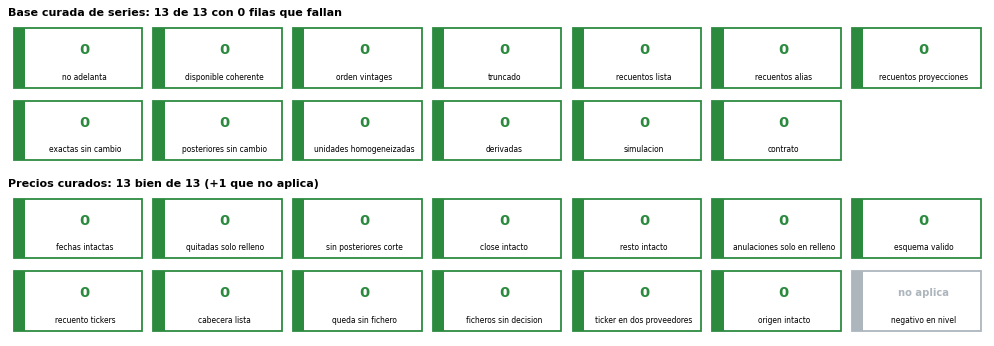

verificacion,comprobadas,fallos,descripcion
no_adelanta,10204276,0,ninguna fecha_publicacion curada anterior a la original (antes de y después del corte)
disponible_coherente,10204276,0,disponible_utc nulo o con primera decisión igual a la fecha curada
orden_vintages,10106283,0,"en cada serie y fecha_referencia, ordenadas por la fecha original, la curada no baja"
truncado,10189834,0,"fecha_publicacion >= fecha_referencia, nada posterior al corte G2 y TimeGate en una muestra (lo visible en una fecha no cambia al quitar lo publicado después)"
recuentos_lista,533,0,series de la base curada = las «queda» de lista_curada.yaml (con historia_previa); sin alias ni proyecciones dentro
recuentos_alias,109,0,filas de la tabla de alias = alias de lista_curada.yaml; cada canónico en la base curada
recuentos_proyecciones,309,0,series de proyecciones = proyecciones.esperadas de preprocesado.yaml
exactas_sin_cambio,8394796,0,las filas vintage_exacto y cierre_mercado no cambian por las capas 1 y 2
posteriores_sin_cambio,14624024,0,las filas publicadas después del corte del tramo (capa 1) o de H.15 (capa 2) no cambian
unidades_homogeneizadas,10189709,0,"homogeneizacion de preprocesado.yaml: escalas a su unidad_nueva, unidades equivalentes con su nombre canónico y sin_escalar sin tocar"


verificacion,estado,fallos,descripcion
fechas_intactas,ok,0,fecha_publicacion y disponible_utc de cada sesión curada iguales a las originales
quitadas_solo_relleno,ok,0,"solo faltan las sesiones posteriores al corte y las velas de relleno fuera de calendario (repiten el cierre, sin volumen ni evento)"
sin_posteriores_corte,ok,0,ninguna sesión curada con fecha_publicacion posterior al corte G2
close_intacto,ok,0,el close de las sesiones que quedan no cambia
resto_intacto,ok,0,"mercado, volumen, dividendo, split, divisa, fuente y descargado no cambian"
anulaciones_solo_en_relleno,ok,0,open/high/low solo cambian a nulo y solo en sesiones con open == close y high == low
esquema_valido,ok,0,cada fichero pasa contrato.validar_precios y el parquet escrito se relee igual
recuento_tickers,ok,0,tickers escritos = tickers «queda» de la lista curada (1616 de 1616)
cabecera_lista,ok,0,las entradas «queda» de la lista curada = las de su cabecera (1616)
queda_sin_fichero,ok,0,ningún ticker «queda» sin fichero en precios/


In [12]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(12.5, 4.4))


def rejilla(ax, nombres, fallos, estados, titulo):
    k = len(nombres)
    cols = 7
    for i, (nom, f, e) in enumerate(zip(nombres, fallos, estados)):
        x, y = i % cols, i // cols
        c = COL_NA if e == 'no aplica' else (COL_OK if f == 0 else COL_MAL)
        ax.add_patch(plt.Rectangle((x + .04, -y - .9), .92, .82, fc='white', ec=c, lw=1.6))
        ax.add_patch(plt.Rectangle((x + .04, -y - .9), .08, .82, fc=c, ec='none'))
        ax.text(x + .55, -y - .38, 'no aplica' if e == 'no aplica' else str(int(f)), ha='center', va='center',
                fontsize=13 if e != 'no aplica' else 9, fontweight='bold', color=c)
        ax.text(x + .55, -y - .75, nom.replace('_', ' '), ha='center', va='center', fontsize=6.8)
    ax.set_xlim(0, cols)
    ax.set_ylim(-((k - 1) // cols + 1), 0)
    ax.axis('off')
    ax.set_title(titulo, fontsize=10, loc='left')


rejilla(a1, ver_s['verificacion'], ver_s['filas_fallan'], ['ok'] * len(ver_s),
        f"Base curada de series: {n(ver_s['filas_fallan'] == 0)} de {len(ver_s)} con 0 filas que fallan")
rejilla(a2, ver_p['verificacion'], ver_p['n_fallos'], ver_p['estado'],
        f"Precios curados: {n(ver_p['estado'] == 'ok')} bien de {n(ver_p['estado'] != 'no aplica')} "
        f"(+{n(ver_p['estado'] == 'no aplica')} que no aplica)")
plt.tight_layout()
plt.show()
display(ver_s.rename(columns={'filas_fallan': 'fallos'})[['verificacion', 'comprobadas', 'fallos', 'descripcion']]
        .astype({'comprobadas': int}).style.hide(axis='index').set_caption('Base curada de series'))
display(ver_p.rename(columns={'n_fallos': 'fallos', 'detalle': 'descripcion'})[['verificacion', 'estado', 'fallos', 'descripcion']]
        .style.hide(axis='index').set_caption('Precios curados'))

**El manifiesto** (`series/curada_manifiesto.json`, la ficha de la construcción) ata la base curada a lo que la produjo: la base de trabajo y los
dos YAML (con tamaño, fecha y firma SHA-256) y las salidas (filas y firma). Si alguno de los YAML cambia, la base curada
deja de corresponderle y hay que reconstruirla. Abajo se comprueba que los YAML de hoy son los mismos y que la base de
trabajo tiene el mismo tamaño y fecha (sin leerla):

In [13]:
def sha(ruta):
    return hashlib.sha256(Path(ruta).read_bytes()).hexdigest()


filas = []
for nombre, e in MAN['entradas'].items():
    ruta = Path(e['ruta'])
    if ruta.suffix == '.yaml':
        igual = sha(ruta) == e['sha256']
    else:
        st = ruta.stat()
        igual = st.st_size == e['tamano'] and st.st_mtime_ns == e['mtime_ns']
    filas.append({'tipo': 'entrada', 'nombre': nombre, 'fichero': ruta.name, 'tamaño_MB': round(e['tamano'] / 1e6, 2),
                  'filas': np.nan, 'sha256': e['sha256'][:12] + '…', 'igual_hoy': igual})
for nombre, e in MAN['salidas'].items():
    filas.append({'tipo': 'salida', 'nombre': nombre, 'fichero': e['fichero'], 'tamaño_MB': round(e['tamano'] / 1e6, 2),
                  'filas': e['filas'], 'sha256': e['sha256'][:12] + '…', 'igual_hoy': np.nan})
print(f"Creado {MAN['creado_utc']} · corte G2 {MAN['corte_g2']} · construcción en {es(R['segundos'])} s · "
      f"verificaciones del manifiesto con fallos: {sum(v != 0 for v in MAN['verificaciones'].values())}")
pd.DataFrame(filas)

Creado 2026-11-20T18:18:25+00:00 · corte G2 2026-11-13 · construcción en 250 s · verificaciones del manifiesto con fallos: 0


,tipo,nombre,fichero,tamaño_MB,filas,sha256,igual_hoy
0,entrada,base_series,base_series.parquet,96.91,NaN,d1f911d2a349…,True
1,entrada,lista_curada,lista_curada.yaml,0.65,NaN,78d3d960dce7…,True
2,entrada,preprocesado,preprocesado.yaml,0.07,NaN,7e582fe7753b…,True
3,salida,base_curada,base_curada.parquet,88.44,10189709.0,9f21d820f66f…,NaN
4,salida,alias,alias.parquet,0.02,109.0,128a6d87d26d…,NaN
5,salida,proyecciones,proyecciones.parquet,0.02,1340.0,2512b61a7b2a…,NaN
6,salida,registro_cambios,registro_cambios.parquet,17.31,1501271.0,3b0f816f2010…,NaN


## 6. Precios curados

**Qué se ve:** lo que cambia en los precios curados. Dos propuestas del EDA se aplican:

- las **velas de relleno fuera de calendario** (días que el mercado tenía cerrado, que repiten el cierre anterior y
  no tienen volumen) **se quitan**;
- las **aperturas de relleno** (sesiones con `open == close` y `high == low`) pasan a **nulo** en open, high y low,
  tanto sin volumen como con volumen (un OHLC plano con volumen tampoco es una apertura ejecutable).

El resto (cierres, volumen, dividendos, splits) no cambia; las demás incidencias del EDA solo dejan un aviso.

**Por qué importa:** la decisión se toma tras el cierre de t y se **ejecuta a la apertura de t+1**
([convención t+1](../../../docs/tfm/arquitectura.md)). Si esa apertura es de relleno, el backtest ejecutaría a un
precio que no existió. Con la apertura a nulo, el backtest sabe que ese día no hay apertura real y tiene que decidir
qué hacer (esperar o usar otra referencia), en vez de creerse un precio inventado.

**Conclusión:** el relleno no se reparte igual: en EE. UU. suma mucho porque hay muchos tickers, pero por ticker pesa
bastante más en algunos índices, fondos y plazas fuera de EE. UU. (el % por plaza sale debajo de la figura).

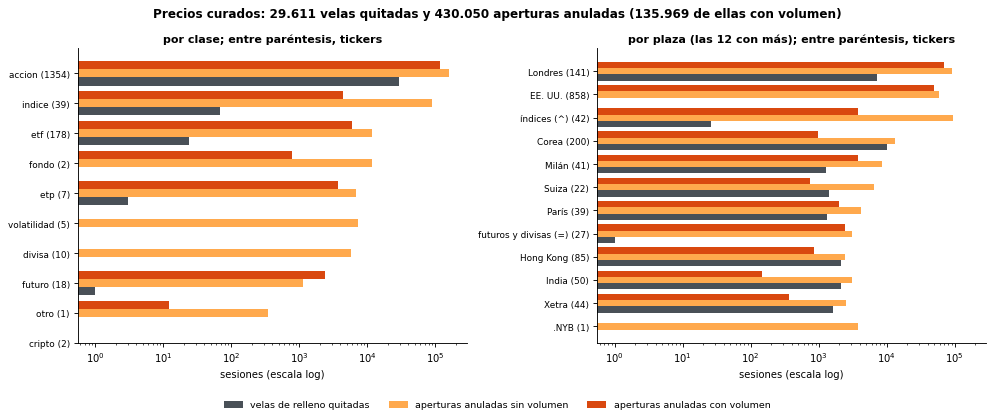

,tickers,sesiones,anuladas,anuladas_con_volumen,velas_quitadas,pct_anuladas
plaza,,,,,,
.NYB,1,14185,3726,0,0,26.27
índices (^),42,415099,95530,3728,26,23.91
Londres,141,918646,90616,70377,7289,17.53
Suiza,22,126122,6577,744,1402,5.80
Milán,41,243445,8604,3730,1280,5.07
futuros y divisas (=),27,169773,3121,2395,1,3.25
París,39,262245,4217,2013,1327,2.38
EE. UU.,858,6397907,58810,49102,0,1.69
Corea,200,981754,13430,972,10072,1.47


In [14]:
PLAZA = {'L': 'Londres', 'KS': 'Corea', 'HK': 'Hong Kong', 'NS': 'India', 'BO': 'India', 'T': 'Tokio', 'PA': 'París',
         'DE': 'Xetra', 'MI': 'Milán', 'MC': 'Madrid', 'AS': 'Ámsterdam', 'SW': 'Suiza', 'SS': 'Shanghái',
         'TW': 'Taiwán', 'TO': 'Toronto', 'AX': 'Australia', 'SA': 'São Paulo'}


def plaza(tk):
    if tk.startswith('cb:'):
        return 'Coinbase'
    if tk.startswith('^'):
        return 'índices (^)'
    if '=' in tk:
        return 'futuros y divisas (=)'
    suf = tk.rsplit('.', 1)[1] if '.' in tk else ''
    return PLAZA.get(suf, f'.{suf}') if suf else 'EE. UU.'


med = pav[pav['tipo'].isin(['apertura_igual_cierre', 'apertura_igual_cierre_con_volumen', 'sesion_fuera_calendario_relleno'])]
piv = med.pivot_table(index='ticker', columns='tipo', values='n', aggfunc='sum', fill_value=0)
piv = piv.reindex(pcr['ticker'], fill_value=0)
assert piv['sesion_fuera_calendario_relleno'].sum() == pcr['velas_quitadas'].sum()
assert piv[['apertura_igual_cierre', 'apertura_igual_cierre_con_volumen']].sum().sum() == pcr['aperturas_anuladas'].sum()
piv['clase'] = piv.index.map(lambda t: LISTA_P[t].get('clase') or 'otro')
piv['plaza'] = piv.index.map(plaza)
MED = [('sesion_fuera_calendario_relleno', 'velas de relleno quitadas', COL_VELA),
       ('apertura_igual_cierre', 'aperturas anuladas sin volumen', '#ffa94d'),
       ('apertura_igual_cierre_con_volumen', 'aperturas anuladas con volumen', '#d9480f')]
fig, axs = plt.subplots(1, 2, figsize=(12.5, 5.2), sharex=True)
for ax, por, top in ((axs[0], 'clase', None), (axs[1], 'plaza', 12)):
    g = piv.groupby(por)[[m for m, _, _ in MED]].sum()
    g = g.loc[g.sum(axis=1).sort_values(ascending=False).index]
    if top:
        g = g.head(top)
    g = g.iloc[::-1]
    y = np.arange(len(g))
    for i, (m, etq, c) in enumerate(MED):
        ax.barh(y + (i - 1) * .27, g[m].where(g[m] > 0), height=.27, color=c, label=etq)
    ntk = piv.groupby(por).size()
    ax.set_yticks(y, [f'{k} ({ntk[k]})' for k in g.index], fontsize=8)
    ax.set_xscale('log')
    ax.set_xlabel('sesiones (escala log)')
    ax.set_title(f'por {por}' + (f' (las {top} con más)' if top else '') + '; entre paréntesis, tickers', fontsize=10)

fig.suptitle(f"Precios curados: {es(pcr['velas_quitadas'].sum())} velas quitadas y "
             f"{es(pcr['aperturas_anuladas'].sum())} aperturas anuladas "
             f"({es(piv['apertura_igual_cierre_con_volumen'].sum())} de ellas con volumen)", fontweight='bold')
fig.legend(*axs[0].get_legend_handles_labels(), loc='lower center', ncol=3, frameon=False, fontsize=8.5)
plt.tight_layout(rect=(0, .06, 1, 1))
plt.show()
pp = piv.assign(ses=pcr.set_index('ticker')['sesiones_despues']).groupby('plaza').agg(
    tickers=('clase', 'size'), sesiones=('ses', 'sum'), anuladas=('apertura_igual_cierre', 'sum'),
    anuladas_con_volumen=('apertura_igual_cierre_con_volumen', 'sum'), velas_quitadas=('sesion_fuera_calendario_relleno', 'sum'))
pp['pct_anuladas'] = (100 * (pp['anuladas'] + pp['anuladas_con_volumen']) / pp['sesiones']).round(2)
pp.sort_values('pct_anuladas', ascending=False).head(10)

Los diez tickers con más aperturas anuladas (en % de sus sesiones curadas):

In [15]:
top = pcr.assign(pct_anuladas=(100 * pcr['aperturas_anuladas'] / pcr['sesiones_despues']).round(1),
                 clase=pcr['ticker'].map(lambda t: LISTA_P[t].get('clase'))).sort_values('aperturas_anuladas',
                                                                                         ascending=False).head(10)
top[['ticker', 'clase', 'desde', 'hasta', 'sesiones_despues', 'aperturas_anuladas', 'pct_anuladas', 'velas_quitadas']]

,ticker,clase,desde,hasta,sesiones_despues,aperturas_anuladas,pct_anuladas,velas_quitadas
1472,VBMFX,fondo,1986-12-11,2026-11-12,10057,10057,100.0,0
1593,^NYA,indice,1965-12-31,2026-11-13,15319,9318,60.8,0
1598,^SKEW,indice,1990-01-02,2026-11-13,9212,9203,99.9,0
1586,^IRX,indice,1960-01-04,2026-11-12,16702,8791,52.6,0
1582,^GSPC,indice,1927-12-30,2026-11-13,24836,8547,34.4,0
1580,^FVX,indice,1962-01-02,2026-11-12,16205,7957,49.1,0
1606,^TNX,indice,1962-01-02,2026-11-12,16205,7956,49.1,0
738,FCIT.L,accion,1968-12-31,2026-11-13,14803,6914,46.7,125
1318,SMT.L,accion,1968-12-31,2026-11-13,14805,6908,46.7,123
354,ALW.L,accion,1969-12-31,2026-11-13,14541,6470,44.5,126


**Sin ninguna apertura.** Hay tickers en los que casi todas las sesiones son de relleno: Yahoo no publica su apertura
(un fondo de inversión, que solo tiene valor liquidativo, o un índice que solo se calcula al cierre). En la base
curada quedan sin apertura y llevan su aviso: no sirven para ejecutar a la apertura de t+1, solo como señal al cierre.

In [16]:
sa = pav[pav['tipo'] == 'sin_apertura'][['ticker', 'n', 'primera', 'ultima', 'accion', 'nota']]
sa.assign(clase=sa['ticker'].map(lambda t: LISTA_P[t].get('clase'))).reset_index(drop=True)

,ticker,n,primera,ultima,accion,nota,clase
0,VBMFX,10057,1986-12-11,2026-11-12,solo aviso,100.0 % de las sesiones curadas sin open (> 99 %): no hay apertura; la ejecución en t+1 tendrá q...,fondo
1,^SKEW,9203,1990-01-02,2026-11-13,solo aviso,99.9 % de las sesiones curadas sin open (> 99 %): no hay apertura; la ejecución en t+1 tendrá qu...,indice


## 7. Cobertura del S&P 500

**Qué se ve:** cuánto de la historia de miembros del S&P 500 tiene precios (`sp500_cobertura_3b1.csv`). Un **tramo** es
un periodo en el que un valor fue miembro del índice; los **días-tramo** suman la duración de todos los tramos. Un tramo
puede tener fichero que solapa con el tramo, fichero que no solapa o no tener fichero; y algunos tickers están
**reutilizados** (el símbolo de Yahoo es hoy de otra empresa, así que ese fichero no es el del miembro antiguo).
**Conclusión:** la cobertura es parcial por el sesgo de supervivencia de Yahoo (los que salieron del índice y dejaron de
cotizar no están); se declara como limitación (solo Yahoo, F3) y su efecto se mide en el backtest.

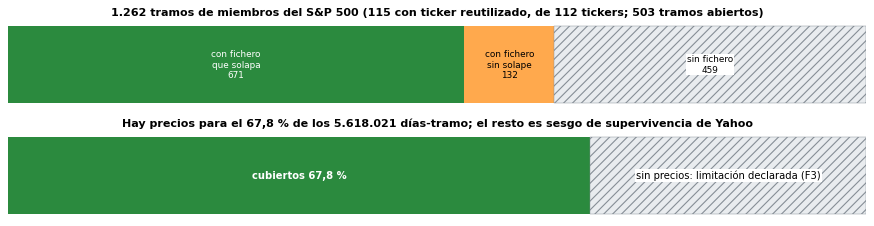

Tramos abiertos (miembros actuales) con fichero que solapa: 503 de 503.


,metrica,dato
0,tramos,1.262
1,tramos_con_fichero,803
2,tramos_con_fichero_que_solapa,671
3,tramos_con_fichero_sin_solape,132
4,tramos_sin_fichero,459
5,tramos_ticker_reutilizado,115
6,tickers_reutilizados,112
7,tramos_abiertos,503
8,tramos_abiertos_con_fichero_que_solapa,503
9,dias_tramo,5.618.021


In [17]:
m = sp5.set_index('metrica')['dato']
fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 2.9))
partes = [('con fichero que solapa', m['tramos_con_fichero_que_solapa'], COL_OK),
          ('con fichero sin solape', m['tramos_con_fichero_sin_solape'], '#ffa94d'),
          ('sin fichero', m['tramos_sin_fichero'], COL_LIM)]
izq = 0
for etq, k, c in partes:
    a1.barh(0, k, left=izq, color=c, ec='#868e96' if c == COL_LIM else 'none', lw=.4, hatch='///' if c == COL_LIM else None)
    a1.text(izq + k / 2, 0, etq.replace('fichero ', 'fichero\n', 1) + f'\n{es(k)}', ha='center', va='center', fontsize=8,
            color='white' if c == COL_OK else 'black', bbox=None if c != COL_LIM else {'fc': 'white', 'ec': 'none', 'pad': 1})
    izq += k
a1.set_xlim(0, izq)
a1.set_title(f"{es(m['tramos'])} tramos de miembros del S&P 500 ({es(m['tramos_ticker_reutilizado'])} con ticker "
             f"reutilizado, de {es(m['tickers_reutilizados'])} tickers; {es(m['tramos_abiertos'])} tramos abiertos)",
             fontsize=10)
cub = m['dias_tramo_cubiertos']
a2.barh(0, cub, color=COL_OK)
a2.barh(0, m['dias_tramo'] - cub, left=cub, color=COL_LIM, ec='#868e96', lw=.4, hatch='///')
a2.set_xlim(0, m['dias_tramo'])
a2.text(cub / 2, 0, f"cubiertos {es(m['pct_dias_tramo_cubiertos'], 1)} %", ha='center', va='center', color='white',
        fontweight='bold')
a2.text(cub + (m['dias_tramo'] - cub) / 2, 0, 'sin precios: limitación declarada (F3)', ha='center', va='center',
        bbox={'fc': 'white', 'ec': 'none', 'pad': 1})
a2.set_title(f"Hay precios para el {es(m['pct_dias_tramo_cubiertos'], 1)} % de los {es(m['dias_tramo'])} días-tramo; "
             "el resto es sesgo de supervivencia de Yahoo", fontsize=10)
for ax in (a1, a2):
    ax.axis('off')
plt.tight_layout()
plt.show()
print(f"Tramos abiertos (miembros actuales) con fichero que solapa: {es(m['tramos_abiertos_con_fichero_que_solapa'])} "
      f"de {es(m['tramos_abiertos'])}.")
sp5.assign(dato=sp5['dato'].map(lambda v: es(v, 2) if v % 1 else es(v)))

## 8. Cómo usarlo

**Qué se ve:** cómo se pide la base curada desde las tools y qué avisos devuelve, con consultas reales en las que solo
se enseñan metadatos (filas, rango de fechas y avisos), nunca valores. **Conclusión:** basta con pasar
`base='curada'`; lo demás (alias, proyecciones, fechas conservadoras, escalas, datos atrasados) lo resuelven las tools y
lo explican en `avisos`.

- `tools.get_serie(id, fecha, base='curada')` y `tools.get_precios(tk, fecha, base='curada')`: mismo TimeGate que la
  base de trabajo (nada publicado después de `fecha`), pero leyendo `base_curada.parquet` y `precios_curados/`. **Es
  la base de los agentes y del backtest**; `base='trabajo'` (por defecto) queda para auditar y construir.
- **Alias resuelto:** pedir un alias sirve su canónico, con un aviso que dice de quién es alias y por qué.
- **Proyecciones:** no salen por `get_serie` (un `KeyError` remite a `tools.get_proyeccion(id, fecha)`), porque no son
  datos de su fecha de referencia.
- **Avisos de la curación:** «fecha no medible» (regla conservadora E4), «tramo conservador» (E5, H.15 y
  reconstruidas), «escala corregida» y, en precios, aperturas nulas y **datos atrasados** (la última sesión visible
  queda lejos de la fecha pedida: ticker sin refrescar o que dejó de cotizar).

In [18]:
atrasado = pcr.loc[pd.to_datetime(pcr['hasta']) < CORTE - pd.Timedelta(days=21), 'ticker'].sort_values().iloc[0]
CONSULTAS = [
    ('serie normal', 'get_serie', 'fred:UNRATE', '2008-10-15'),
    ('alias resuelto', 'get_serie', 'ust:PAR.10Y', '2008-10-15'),
    ('tramo conservador (E5)', 'get_serie', 'fred:ICSA', '2005-03-01'),
    ('fecha no medible (E4)', 'get_serie', 'ecb:EXR.D.USD.EUR', '2020-03-16'),
    ('escala corregida', 'get_serie', 'fred:TOTALSL', '2020-01-15'),
    ('proyección', 'get_proyeccion', 'imf:WEO.USA.NGDP_RPCH.PROY.H1', str(CORTE.date())),
    ('aperturas nulas', 'get_precios', 'AAPL', str(CORTE.date())),
    ('datos atrasados', 'get_precios', atrasado, str(CORTE.date())),
]
filas, avisos = [], []
for caso, f, id_, fecha in CONSULTAS:
    if f == 'get_precios':
        r_ = tools.get_precios(id_, fecha, base='curada', divisa='original')
        d, servida, col = r_.datos, ', '.join(r_.tickers), 'sesion'
        extra = f"{n(d['open'].isna())} sin apertura"
    elif f == 'get_proyeccion':
        r_ = tools.get_proyeccion(id_, fecha)
        d, servida, col, extra = r_.datos, r_.serie, 'fecha_referencia', f"edición {', '.join(sorted(set(r_.datos['edicion'])))}"
    else:
        r_ = tools.get_serie(id_, fecha, base='curada')
        d, servida, col, extra = r_.datos, r_.serie, 'fecha_referencia', r_.unidad
    filas.append({'caso': caso, 'consulta': f"{f}('{id_}', '{fecha}')", 'servida': servida, 'filas': len(d),
                  'desde': d[col].min().date(), 'hasta': d[col].max().date(), 'detalle': extra, 'avisos': len(r_.avisos)})
    avisos += [(caso, a) for a in r_.avisos]
try:
    tools.get_serie('imf:WEO.USA.NGDP_RPCH.PROY.H1', str(CORTE.date()), base='curada')
except KeyError as e:
    print('get_serie de una proyección en modo curado →', 'KeyError:', str(e)[:150], '…')
display(pd.DataFrame(filas))
for caso, a in avisos:
    print(f'[{caso}] {a[:230]}' + ('…' if len(a) > 230 else ''))

get_serie de una proyección en modo curado → KeyError: "serie 'imf:WEO.USA.NGDP_RPCH.PROY.H1': es una proyección (tabla aparte de la base curada, no un dato de su fecha de referencia): usa get_proyeccion(' …


,caso,consulta,servida,filas,desde,hasta,detalle,avisos
0,serie normal,"get_serie('fred:UNRATE', '2008-10-15')",fred:UNRATE,729,1948-01-01,2008-09-01,% de la población activa,1
1,alias resuelto,"get_serie('ust:PAR.10Y', '2008-10-15')",fred:DGS10,11680,1962-01-02,2008-10-14,% anual,2
2,tramo conservador (E5),"get_serie('fred:ICSA', '2005-03-01')",fred:ICSA,1982,1967-01-07,2004-12-25,número de peticiones,2
3,fecha no medible (E4),"get_serie('ecb:EXR.D.USD.EUR', '2020-03-16')",ecb:EXR.D.USD.EUR,5427,1999-01-04,2020-03-13,USD por 1 EUR,1
4,escala corregida,"get_serie('fred:TOTALSL', '2020-01-15')",fred:TOTALSL,923,1943-01-01,2019-11-01,millones de USD,1
5,proyección,"get_proyeccion('imf:WEO.USA.NGDP_RPCH.PROY.H1', '2026-11-13')",imf:WEO.USA.NGDP_RPCH.PROY.H1,2,2025-01-01,2026-01-01,"edición 2025-10, 2026-10",2
6,aperturas nulas,"get_precios('AAPL', '2026-11-13')",AAPL,11574,1980-12-12,2026-11-13,28 sin apertura,1
7,datos atrasados,"get_precios('000001.SS', '2026-11-13')",000001.SS,7091,1997-07-02,2026-10-13,0 sin apertura,1


[serie normal] 27 periodos anteriores a ALFRED (primer vintage 1960-03-15): llevan el valor de ese primer vintage, ya revisado, con la fecha de la regla previa (lag_fijo): posible fuga de revisiones y fecha de publicación aproximada
[alias resuelto] 'ust:PAR.10Y': alias de fred:DGS10: se sirve el canónico (D8: |Pearson| 1.000 (diaria) con fred:DGS10, regla en estrella)
[alias resuelto] fecha de publicación del tramo conservador (antes del corte de lista_curada.yaml la fecha no es fiable: se retrasa con la regla conservadora) en 10852 periodos: tramo conservador de H.15 diario antes de 2005-06-28: 7D más (preproc…
[tramo conservador (E5)] 1982 periodos anteriores a ALFRED (primer vintage 2009-05-28): llevan el valor de ese primer vintage, ya revisado, con la fecha de la regla previa (lag_fijo): posible fuga de revisiones y fecha de publicación aproximada
[tramo conservador (E5)] fecha de publicación del tramo conservador (antes del corte de lista_curada.yaml la fecha no es fiable: se re

## 9. Limitaciones y lo que queda

**Qué se ve:** lo que la base curada todavía no tiene o no puede tener, ahora que el 3b está hecho. **Conclusión:** lo
declarado como limitación no tiene fuente gratuita y legal y se documenta (las ediciones antiguas del WEO, las series que
sus fuentes no publican, la historia que Yahoo recorta y los ficheros que no llegan al corte); la conversión a USD de lo
que cotiza en yuanes queda pendiente de revisar; la historia más antigua de algunos alias solo está en la base de
trabajo; y el paso 5 cierra el tema.

In [19]:
apl = est[est['estado_3b'] == 'aplazado']
lim = est[est['estado_3b'] == 'limitacion_declarada']
corto = lambda s: s.str.split(' · ').str[-1].str.slice(0, 150)
ed_lim = lim[lim['tipo'] == 'ediciones']
no_pub = lim[(lim['tipo'] == 'series') & lim['id'].str.match(r'(eurostat|oecd):')]
avl = pav[pav['tipo'] == 'aviso_lista']
recortada = avl.loc[avl['nota'].str.contains('historia recortada'), 'ticker'].nunique()
ucits_baja = avl.loc[avl['nota'].str.contains('correlación semanal baja'), 'ticker'].nunique()
no_llega = pav.loc[pav['tipo'] == 'no_llega_corte', 'ticker'].nunique()
LIMS = [
    ('ediciones antiguas del WEO', f"{len(ed_lim)} ediciones",
     next((x.strip() for x in str(ed_lim['motivo_3b'].iloc[0]).split(';') if 'imf.org' in x), '—') if len(ed_lim) else '—'),
    ('series que la fuente no publica', ', '.join(no_pub['id']), 'zona euro cambiante de Eurostat; CLI EA20 y paro de China de la OCDE'),
    ('historia recortada por Yahoo', f"{recortada} UCITS", 'Yahoo empieza después del lanzamiento: se guarda lo que hay (F3)'),
    ('alias UCITS poco parecidos', f"{ucits_baja} pares", 'correlación semanal con su ETF de EE. UU. por debajo de 0,90: aviso'),
    ('ficheros que no llegan al corte', f"{no_llega} ficheros", 'Yahoo revisa sesiones ya guardadas o el ticker se reutilizó: se conserva lo guardado'),
    ('conversión a USD del CNY', 'ver abajo', 'falta el fixing del BCE en parte de la historia: pendiente de revisar'),
    ('aplazado', ', '.join(apl['id']) or '—', corto(apl['motivo_3b']).iloc[0] if len(apl) else '—'),
]
display(pd.DataFrame(LIMS, columns=['qué', 'cuánto', 'por qué']).style.hide(axis='index'))
print(f"Limitaciones declaradas del 3b: {len(lim)} filas · " + ', '.join(f'{t} {k}' for t, k in lim['tipo'].value_counts().items()))
(lim.assign(motivo_corto=corto(lim['motivo_3b']).str.slice(0, 110))
    .groupby(['tipo', 'motivo_corto']).agg(filas=('id', 'size'), ejemplos=('id', lambda s: ', '.join(s.head(3))))
    .reset_index().sort_values('filas', ascending=False).head(12).reset_index(drop=True))

qué,cuánto,por qué
ediciones antiguas del WEO,34 ediciones,el archivo de www.imf.org no es accesible (robots.txt con 403 de Akamai: todo prohibido) y DBnomics no se usa
series que la fuente no publica,"eurostat:ei_bssi_m_r2.EA, eurostat:une_rt_m.EA, oecd:LI_AA.EA20, oecd:UNEMP.CHN",zona euro cambiante de Eurostat; CLI EA20 y paro de China de la OCDE
historia recortada por Yahoo,18 UCITS,Yahoo empieza después del lanzamiento: se guarda lo que hay (F3)
alias UCITS poco parecidos,23 pares,"correlación semanal con su ETF de EE. UU. por debajo de 0,90: aviso"
ficheros que no llegan al corte,21 ficheros,Yahoo revisa sesiones ya guardadas o el ticker se reutilizó: se conserva lo guardado
conversión a USD del CNY,ver abajo,falta el fixing del BCE en parte de la historia: pendiente de revisar
aplazado,baseline:6040_europeo,"no es un ticker: es una cartera derivada (60 % CSPX.L, 40 % EUNA.DE desde 2017-11). Los precios ya están, también el proxy previo de EUNA.DE (BNDX, lo"


Limitaciones declaradas del 3b: 124 filas · serie_sospechosa 37, ediciones 34, excepcion_refresco 24, redescarga 8, series 7, precios 5, deslistado 2, constituyentes 2, limitacion_agregada 2, refresco 1, vintages 1, fechas 1


,tipo,motivo_corto,filas,ejemplos
0,serie_sospechosa,serie sospechosa (ticker reciclado o datos basura: saltos sin split o cierres repetidos): rehace...,37,"001440.KS, 032640.KS, ABI"
1,ediciones,"limitación declarada (G3): ninguna API del FMI sirve la edición (la API SDMX solo tiene 2025-04,...",34,"imf_weo:edicion:2008-04, imf_weo:edicion:2008-10, imf_weo:edicion:2009-04"
2,excepcion_refresco,Yahoo revisa una sesión ya guardada (2026-09-07); se conserva lo guardado,10,"ALC.SW, CFR.SW, GIVN.SW"
3,series,"PCPI, EMPLOY y RUC sin filas por diseño: todos sus vintages son posteriores al primero de ALFRED...",3,"philly:EMPLOY, philly:PCPI, philly:RUC"
4,excepcion_refresco,Yahoo revisa una sesión ya guardada (2026-10-13); se conserva lo guardado,2,"EXO.AS, JD.L"
5,redescarga,deslistado o adquirido: sale del S&P 500 el 2026-08-18 (fja05680),2,"AVB, EQR"
6,excepcion_refresco,Yahoo revisa open/high/low de toda la historia tras la fusión con Skydance (2025); la historia s...,1,PARA
7,constituyentes,G1: prioridad baja sin fuente gratuita y legal,1,constituyentes:nikkei225_ibovespa
8,constituyentes,fja05680/sp500 refrescado el 2026-11-20 sin cambios: su último cambio es del 2026-08-18. Los cam...,1,constituyentes:sp500_posterior_fja
9,deslistado,ticker reutilizado: el fichero no es el miembro del S&P (fichero 2001-01-02 a 2018-02-22): falta...,1,GR


**Pendiente de revisar: la conversión a USD de lo que cotiza en yuanes (CNY).** Al pedir precios en USD, las tools
convierten con el fixing del BCE visible en la fecha. Para el CNY falta ese fixing en parte de la historia y la
conversión sale nula (NaN) en esas sesiones. Hay que revisarlo en las tools (otro cruce, por ejemplo vía USD/CNY de
Yahoo) o en el FX de la base. Se cuenta abajo, sin valores:

In [20]:
invp = pd.read_csv(T / 'inventario_precios.csv', dtype={'ticker': str})
cny = sorted(set(invp.loc[invp['divisa'] == 'CNY', 'ticker']) & set(pcr['ticker']))
filas_cny = []
for tk in cny:
    if tk.endswith('=X'):          # el propio tipo de cambio: no se convierte
        continue
    r_ = tools.get_precios(tk, str(CORTE.date()), base='curada', divisa='USD')
    filas_cny.append({'ticker': tk, 'sesiones': len(r_.datos), 'sin_fx_usd': n(r_.datos['fx_usd'].isna()),
                      'aviso': next((a for a in r_.avisos if 'fixing' in a), '—')[:120]})
pd.DataFrame(filas_cny).style.hide(axis='index')

ticker,sesiones,sin_fx_usd,aviso
000001.SS,7091,618,618 filas en CNY sin fixing del BCE visible en 2026-11-13 anterior o igual a su fecha: valores NaN


**La historia antigua de los alias.** Un alias no entra en la base curada: se sirve su canónico. Si el alias empezaba
antes que su canónico (por ejemplo, una fuente académica con historia larga frente a la oficial de FRED), esa historia
previa **solo está en la base de trabajo** (`base='trabajo'`). Los que la tienen antes del corte de D1 y cuyo canónico
no, ya se quedan como historia previa (sección 2); los demás:

In [21]:
pub = inv.set_index('id')['pub_desde']
al = pd.DataFrame([{'alias': k, 'canonico': v.get('alias_de')} for k, v in LISTA.items() if v['decision'] == 'alias'])
al['pub_alias'] = pd.to_datetime(al['alias'].map(pub))
al['pub_canonico'] = pd.to_datetime(al['canonico'].map(pub))
al['anos_previos'] = ((al['pub_canonico'] - al['pub_alias']).dt.days / 365.25).round(1)
mas = al[al['anos_previos'] > 0].sort_values('anos_previos', ascending=False)
print(f"{len(mas)} de {len(al)} alias empiezan antes que su canónico; {n(mas['pub_alias'] < pd.Timestamp('2000-01-01'))} "
      "de ellos con historia anterior a 2000 que solo está en la base de trabajo.")
mas.head(10).assign(pub_alias=lambda d: d['pub_alias'].dt.date, pub_canonico=lambda d: d['pub_canonico'].dt.date).reset_index(drop=True)

27 de 109 alias empiezan antes que su canónico; 26 de ellos con historia anterior a 2000 que solo está en la base de trabajo.


,alias,canonico,pub_alias,pub_canonico,anos_previos
0,shiller:LONGRATE,fred:GS10,1871-03-01,1953-05-01,82.2
1,fred:DFF,fred:EFFR,1954-07-02,2000-07-05,46.0
2,wb:CAN.FP.CPI.TOTL.ZG,oecd:CP.CAN,1961-12-31,1999-03-01,37.2
3,wb:ITA.FP.CPI.TOTL.ZG,oecd:CP.ITA,1961-12-31,1999-03-01,37.2
4,wb:GBR.FP.CPI.TOTL.ZG,oecd:CP.GBR,1961-12-31,1999-03-01,37.2
5,wb:FRA.FP.CPI.TOTL.ZG,oecd:CP.FRA,1961-12-31,1999-03-01,37.2
6,wb:JPN.FP.CPI.TOTL.ZG,oecd:CP.JPN,1961-12-31,1999-03-01,37.2
7,wb:DEU.FP.CPI.TOTL.ZG,oecd:CP.DEU,1961-12-31,1999-03-01,37.2
8,wb:ITA.NY.GDP.MKTP.KD.ZG,eurostat:namq_10_gdp.Q.CLV_PCH_SM.SCA.B1GQ.IT,1962-12-31,1997-06-10,34.4
9,wb:DEU.NY.GDP.MKTP.KD.ZG,eurostat:namq_10_gdp.Q.CLV_PCH_SM.SCA.B1GQ.DE,1962-12-31,1992-06-10,29.4


**El paso 5** (`05_resultado`): cómo ha quedado el dataset, un catálogo legible para los agentes (id, descripción,
frecuencia, desde y fiabilidad de la fecha), la última verificación, la destilación del plan en el README del tema y la
PR. El 3b-2 ya está hecho y la base curada se construyó después; si se vuelve a refrescar, se reconstruye con esta
misma orden.